# Guía 6 - ejercicio 16

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter
from matplotlib import style
style.use('default')

### Función para graficar Espectogramas

In [36]:
def grafEspectrograma(signal, frameRate, start_x=0, end_x=0, titulo='Titulo',
                      max_frec=0, calc_fund_frec=False, nfft=1024, overlap=512):
    """
    Función para calcular y graficar el espectrograma de una señal.

    Parámetros:
        signal: numpy.ndarray - la señal a analizar
        frameRate: float - el número de muestras por segundo de la señal
        start_x: float - inicio del eje x (default: 0)
        end_x: float - fin del eje x (default: 0 -> maximo)
        titulo: str - título del gráfico (default: 'Titulo')
        max_frec: float - frecuencia máxima (default: 0 -> maximo)
        calc_fund_frec: bool - calcular la frecuencia fundamental y graficarla (default: False)
        nfft: int - numero de puntos para la FFT (default: 1024)

    Return:
        None
    """
    # Convertir los tiempos a índices
    start_index = int(start_x * frameRate)
    end_index = int(end_x * frameRate) if end_x != 0 else len(signal)

    # Se ventanea la señal
    window_signal = signal[start_index:end_index]

    # Calcular y graficar el espectrograma
    plt.figure(figsize=(10, 4))
    """
    Pxx: Es la matriz del espectrograma (t,f).
    freqs: Es la lista de frecuencias.
    bins: Es la lista de tiempos.
    im: Es la imagen del espectrograma.
    """
    Pxx, freqs, bins, im = plt.specgram(
        window_signal, NFFT=nfft, Fs=frameRate, noverlap=overlap, cmap='viridis')

    plt.colorbar(im).set_label('Intensidad [dB]', fontsize=14)

    if end_x:
        plt.title(
            f'Espectrograma {titulo} (intervalo {start_x}s a {end_x}s)\n', fontsize=18)
    else:
        end_x = round(len(signal)/frameRate, 1)
        plt.title(
            f'Espectrograma {titulo} (intervalo {start_x}s a {end_x}s)\n', fontsize=18)
    plt.xlabel("Tiempo [s]", fontsize=14)
    plt.ylabel("Frecuencia [Hz]", fontsize=14)
    plt.tick_params(axis='both', which='major', labelsize=14)
    plt.minorticks_on()

    # Limitar el rango de frecuencias mostrado (si se especifica)
    if max_frec:
        plt.ylim(0, max_frec)

    # Calcular y marcar la frecuencia fundamental en cada ventana si es necesario
    if calc_fund_frec:
        fund_freqs = []
        for i in range(Pxx.shape[1]):  # shape devuelve cantidad de columnas
            # Encontrar la frecuencia fundamental en cada ventana (columna)
            fund_index = np.argmax(Pxx[:, i])
            fund_freqs.append(freqs[fund_index])
            # Fund_index toma la fundamental del arreglo freqs, fund_freqs.append lo guarda en el arreglo fund_freqs

        # Dibujar las frecuencias fundamentales en el espectrograma
        plt.plot(bins, fund_freqs, color='purple', linestyle="dotted",
                 linewidth=1.2, label="Frecuencia Fundamental")
        plt.legend()

    # Usar notación de ingeniería para los ejes
    formatter = EngFormatter()
    plt.gca().yaxis.set_major_formatter(formatter)
    plt.gca().xaxis.set_major_formatter(formatter)

    plt.grid(which='major', linestyle='-',
             linewidth='0.5', color='black', alpha=0.5)
    plt.grid(which='minor', linestyle='-',
             linewidth='0.5', color='black', alpha=0.1)

    plt.show()

## Caso 1
$x(t)=\cos{(2\pi 100t)}$, $0< t<1$

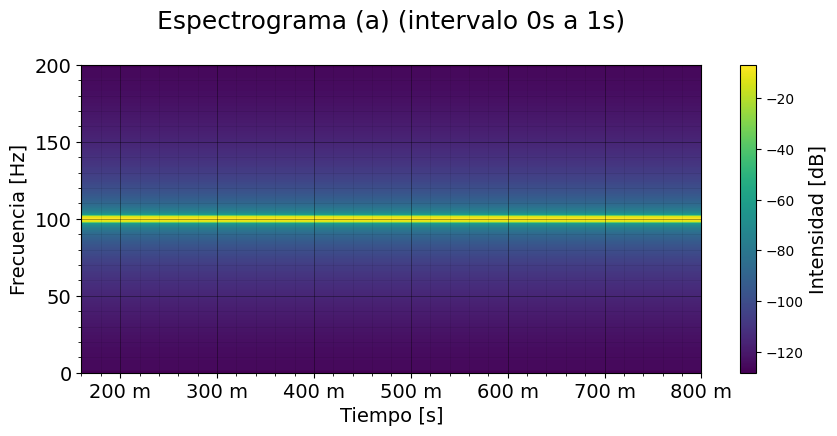

In [37]:
# Parámetros de la señal
t_min, t_max = 0, 1  # Intervalo de tiempo
sampling_rate = 400  # Frecuencia de muestreo en Hz

# Generar el tiempo discreto
t = np.linspace(t_min, t_max, int(
    sampling_rate * (t_max - t_min)), endpoint=False)

x_t = np.cos(2 * np.pi * 100 * t)

grafEspectrograma(signal=x_t, frameRate=sampling_rate,
                  titulo="(a)", start_x=t_min, end_x=t_max, nfft=256, overlap=128)

## Caso 2
$x(t) = [1 + \cos(2\pi10t)] \cos(2\pi100t)$, $0< t<1$

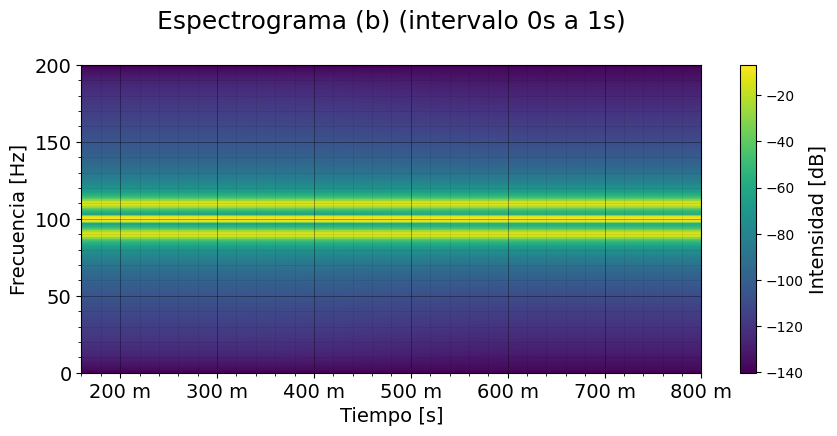

In [38]:
# Parámetros de la señal
t_min, t_max = 0, 1  # Intervalo de tiempo
sampling_rate = 400  # Frecuencia de muestreo en Hz

# Generar el tiempo discreto
t = np.linspace(t_min, t_max, int(
    sampling_rate * (t_max - t_min)), endpoint=False)

x_t = (1 + np.cos(2 * np.pi * 10 * t)) * np.cos(2 * np.pi * 100 * t)

grafEspectrograma(signal=x_t, frameRate=sampling_rate,
                  titulo="(b)", start_x=t_min, end_x=t_max, nfft=256, overlap=128)

## Caso 3
$x(t)=\cos{2\pi 100t^2}$, $0< t<1$

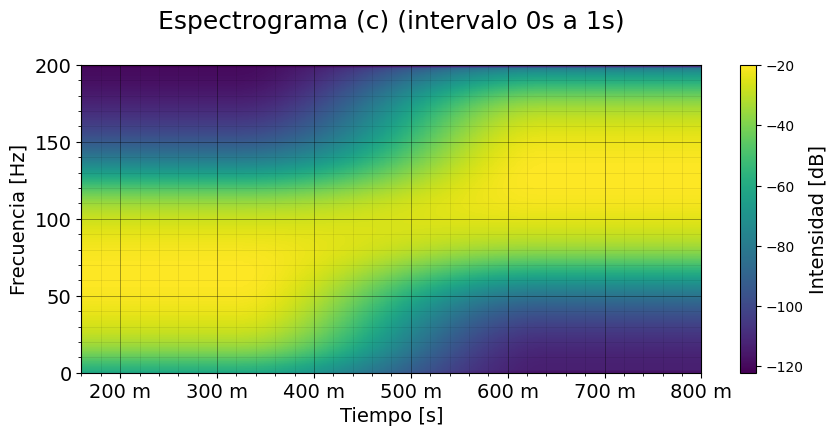

In [39]:
# Parámetros de la señal
t_min, t_max = 0, 1  # Intervalo de tiempo
sampling_rate = 400  # Frecuencia de muestreo en Hz

# Generar el tiempo discreto
t = np.linspace(t_min, t_max, int(
    sampling_rate * (t_max - t_min)), endpoint=False)

x_t = np.cos(2 * np.pi * 100 * (t**2))

grafEspectrograma(signal=x_t, frameRate=sampling_rate,
                  titulo="(c)", start_x=t_min, end_x=t_max, nfft=256, overlap=128)